# Fashion-MNIST — GA-AD: Genetic Algorithm Adaptive Dropout

**Updated to follow the revised GA-AD methodology implemented in the MNIST digit-recognition notebook.**

This notebook ports the revised MNIST implementation to Fashion-MNIST while preserving the Fashion-MNIST CSV inputs, ten-class labels, class names, and official test set.

The controlled comparison is:
- No Dropout
- Conventional element-wise Dropout
- Random fixed-cardinality neuron masks
- Q-guided low-importance neuron masking
- GA-AD with diverse elite-mask resampling

The GA optimizes a fixed-cardinality mask using the Q importance score only. It does **not** use validation loss or the GA holdout to score candidate masks. A different elite candidate is sampled for each mini-batch.

## 1. Imports and reproducibility

In [2]:
import os, random, warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.utils import to_categorical

SEED = 42
SEEDS = [42, 7, 123]
EPOCHS = 35
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EARLY_STOPPING_PATIENCE = 6
LR_PATIENCE = 3

TRAIN_PATH = "/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv"
TEST_PATH  = "/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv"

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

set_seed(SEED)
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU(s):", len(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
Keras: 3.13.2
GPU(s): 0


## 2. Load and inspect Fashion-MNIST

Training CSV: (60000, 785)
Official test CSV: (10000, 785)
Missing values — train: 0
Missing values — test : 0
Duplicate training rows: 43

Class distribution:


label
T-shirt/top    6000
Trouser        6000
Pullover       6000
Dress          6000
Coat           6000
Sandal         6000
Shirt          6000
Sneaker        6000
Bag            6000
Ankle boot     6000
Name: count, dtype: int64

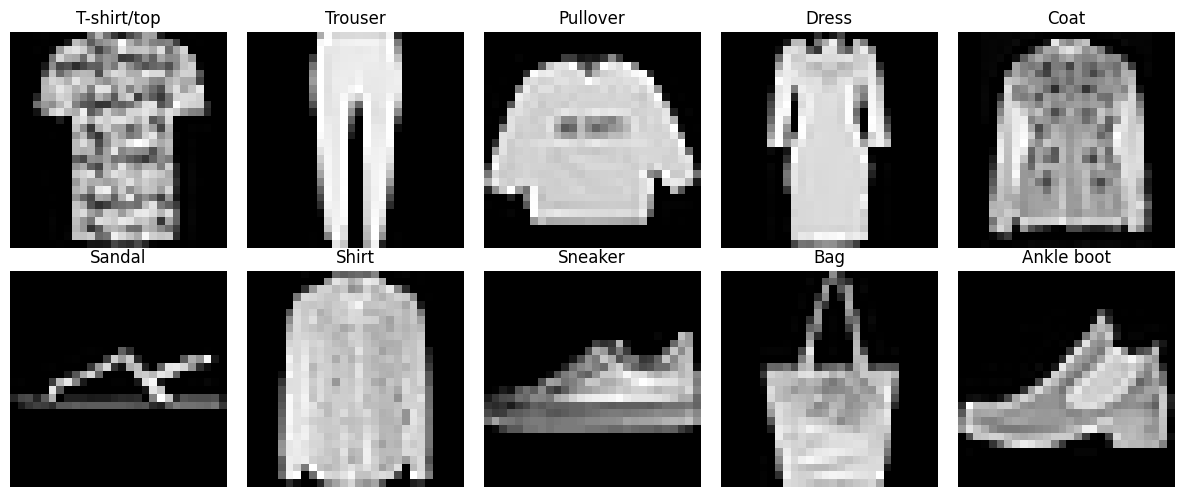

In [3]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

assert "label" in train_df.columns and "label" in test_df.columns
assert train_df.isnull().sum().sum() == 0
assert test_df.isnull().sum().sum() == 0

print("Training CSV:", train_df.shape)
print("Official test CSV:", test_df.shape)
print("Missing values — train:", train_df.isnull().sum().sum())
print("Missing values — test :", test_df.isnull().sum().sum())
print("Duplicate training rows:", train_df.duplicated().sum())
print("\nClass distribution:")
display(train_df["label"].value_counts().sort_index().rename(dict(enumerate(CLASS_NAMES))))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for cls, ax in enumerate(axes.ravel()):
    sample = train_df.loc[train_df.label == cls].iloc[0]
    ax.imshow(sample.drop("label").to_numpy().reshape(28, 28), cmap="gray")
    ax.set_title(CLASS_NAMES[cls])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Preprocessing and leakage-aware data partition

The official Fashion-MNIST test CSV is isolated until final evaluation. The 60,000-row training CSV is split into:
- **42,000 training examples** for gradient updates and Q estimation
- **8,000 GA holdout examples** reserved for post-training diagnostics only
- **10,000 validation examples** for early stopping and model selection

The GA holdout is not used to optimize candidate masks. Validation loss is not part of GA fitness.

In [4]:
X_all = train_df.drop(columns="label").to_numpy(dtype=np.float32) / 255.0
y_all_int = train_df["label"].to_numpy(dtype=np.int64)

X_test = test_df.drop(columns="label").to_numpy(dtype=np.float32) / 255.0
y_test_int = test_df["label"].to_numpy(dtype=np.int64)

# First reserve the early-stopping / model-selection validation partition.
X_dev, X_val, y_dev, y_val_int = train_test_split(
    X_all, y_all_int, test_size=10000, random_state=42, stratify=y_all_int
)

# Reserve a separate GA diagnostic partition from the remaining development data.
X_train, X_ga_holdout, y_train_int, y_ga_holdout_int = train_test_split(
    X_dev, y_dev, test_size=8000, random_state=43, stratify=y_dev
)

y_train = to_categorical(y_train_int, num_classes=10).astype(np.float32)
y_val = to_categorical(y_val_int, num_classes=10).astype(np.float32)
y_test = to_categorical(y_test_int, num_classes=10).astype(np.float32)
y_ga_holdout = to_categorical(y_ga_holdout_int, num_classes=10).astype(np.float32)

print("Training:", X_train.shape)
print("GA holdout (diagnostic only):", X_ga_holdout.shape)
print("Validation:", X_val.shape)
print("Official test:", X_test.shape)

Training: (42000, 784)
GA holdout (diagnostic only): (8000, 784)
Validation: (10000, 784)
Official test: (10000, 784)


## 4. Shared MLP architecture and conventional baselines

In [5]:
def build_base_mlp(input_dim=784, name="Fashion_MLP"):
    """Shared 512-256-128 MLP without dropout layers."""
    model = models.Sequential(name=name)
    model.add(layers.Input(shape=(input_dim,)))
    model.add(layers.Dense(512, activation="relu", kernel_initializer="he_normal", name="dense_512"))
    model.add(layers.Dense(256, activation="relu", kernel_initializer="he_normal", name="dense_256"))
    model.add(layers.Dense(128, activation="relu", kernel_initializer="he_normal", name="dense_128"))
    model.add(layers.Dense(10, activation="softmax", name="output"))
    return model

def build_dropout_mlp(dropout_rate=0.3, input_dim=784, name="Fashion_StandardDropout"):
    """Same MLP with conventional element-wise Keras dropout after each hidden layer."""
    model = models.Sequential(name=name)
    model.add(layers.Input(shape=(input_dim,)))
    for units in (512, 256, 128):
        model.add(layers.Dense(units, activation="relu", kernel_initializer="he_normal",
                               name=f"dense_{units}"))
        model.add(layers.Dropout(dropout_rate, name=f"dropout_{units}"))
    model.add(layers.Dense(10, activation="softmax", name="output"))
    return model

def compile_model(model, learning_rate=LEARNING_RATE):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def get_callbacks(patience_es=EARLY_STOPPING_PATIENCE, patience_lr=LR_PATIENCE):
    return [
        callbacks.EarlyStopping(
            monitor="val_loss", patience=patience_es,
            restore_best_weights=True, verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=patience_lr,
            min_lr=1e-6, verbose=1
        )
    ]

def fit_keras_baseline(model, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1):
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=batch_size, shuffle=True,
        callbacks=get_callbacks(), verbose=verbose
    )
    return history

## 5. GA-AD importance modules

### Module A — Activation-gradient importance

For each hidden unit, estimate the batch mean of:

\[
I_i = \mathbb{E}_{(x,y)\sim B}\left[\left|h_i\frac{\partial\mathcal{L}}{\partial h_i}\right|\right].
\]

An exponential moving average (EMA) stabilizes the estimate across calibration batches and epochs. Robust percentile scaling limits the influence of extreme values.

### Module B — Polynomial descriptor removed

The earlier polynomial descriptor was a deterministic transform of the same score and did not provide independent information. It is intentionally omitted.

### Module C — Q semantics

Q is the normalized activation-gradient importance. **High Q means protect; low Q means eligible to drop.**

In [6]:
class GradientTracker:
    """EMA of mean |activation * dL/dactivation|, a first-order saliency proxy."""
    def __init__(self, layer_sizes, rho=0.9, epsilon=1e-8):
        self.rho, self.epsilon = rho, epsilon
        self.ema = {k: np.zeros(v, dtype=np.float64) for k, v in layer_sizes.items()}
        self.initialized = {k: False for k in layer_sizes}

    def update(self, scores):
        for name, score in scores.items():
            score = np.asarray(score, dtype=np.float64)
            if not self.initialized[name]:
                self.ema[name] = score.copy()
                self.initialized[name] = True
            else:
                self.ema[name] = self.rho * self.ema[name] + (1.0 - self.rho) * score

    def get_normalized_scores(self, name):
        x = self.ema[name]
        lo, hi = np.percentile(x, 5), np.percentile(x, 95)
        if hi - lo < self.epsilon:
            return np.full_like(x, 0.5, dtype=np.float64)
        return np.clip((x - lo) / (hi - lo + self.epsilon), 0.0, 1.0)

def compute_Q(importance):
    """Normalized importance: high Q units are preferentially retained."""
    return np.asarray(importance, dtype=np.float64)

def compute_D_from_rate(layer_names, p):
    if not 0.0 <= p < 1.0:
        raise ValueError("p must be in [0, 1).")
    return {name: min(int(round(size * p)), size - 1)
            for name, size in layer_names.items()}

# Candidate rates are explicitly declared; each p must be trained from scratch.
P_GRID = (0.1, 0.2, 0.3, 0.4)

## 6. Module D — Genetic mask optimizer

The GA searches masks with a fixed number of active units. Fitness is the mean Q importance retained by a mask:

\[
F(m)=\frac{\sum_i Q_i m_i}{\max(\sum_i m_i,1)}.
\]

This is an importance-retention heuristic, **not** a validation or generalization objective. The population uses crossover, mutation, and cardinality repair. The optimizer returns several distinct elite masks rather than one fixed winner.

In [7]:
class GeneticMaskOptimizer:
    """Search fixed-cardinality masks using Q only; validation data never score masks."""
    def __init__(self, N, D_star, Q, population_size=24, generations=8,
                 mutation_rate=0.04, elite_frac=0.25, seed=42):
        self.N, self.D, self.A = N, D_star, N - D_star
        self.Q = np.asarray(Q, dtype=np.float64)
        self.pop_size, self.generations = population_size, generations
        self.mutation_rate = mutation_rate
        self.n_elite = max(2, int(elite_frac * population_size))
        self.rng = np.random.RandomState(seed)

    def _random_mask(self):
        mask = np.zeros(self.N, dtype=np.int8)
        mask[self.rng.choice(self.N, self.A, replace=False)] = 1
        return mask

    def _repair(self, mask):
        mask = mask.copy()
        active, inactive = np.where(mask == 1)[0], np.where(mask == 0)[0]
        if len(active) > self.A:
            remove = active[np.argsort(self.Q[active])[:len(active) - self.A]]
            mask[remove] = 0
        elif len(active) < self.A:
            add = inactive[np.argsort(-self.Q[inactive])[:self.A - len(active)]]
            mask[add] = 1
        return mask

    def _fitness(self, mask):
        return float(np.sum(self.Q * mask) / max(self.A, 1))

    def evolve(self):
        population = np.asarray([self._random_mask() for _ in range(self.pop_size)])
        for _ in range(self.generations):
            fitness = np.asarray([self._fitness(m) for m in population])
            elite = population[np.argsort(-fitness)[:self.n_elite]].copy()
            next_population = list(elite)
            while len(next_population) < self.pop_size:
                parent_a = elite[self.rng.randint(len(elite))]
                parent_b = elite[self.rng.randint(len(elite))]
                child = np.where(self.rng.rand(self.N) < 0.5,
                                 parent_a, parent_b).astype(np.int8)
                flip = self.rng.rand(self.N) < self.mutation_rate
                child[flip] = 1 - child[flip]
                next_population.append(self._repair(child))
            population = np.asarray(next_population)

        fitness = np.asarray([self._fitness(m) for m in population])
        unique_elites = []
        for idx in np.argsort(-fitness):
            candidate = population[idx]
            if not any(np.array_equal(candidate, old) for old in unique_elites):
                unique_elites.append(candidate.copy())
            if len(unique_elites) >= self.n_elite:
                break
        return np.asarray(unique_elites, dtype=np.float32)

## 7. Module E — GA-AD custom training loop

The custom loop applies masks to the three hidden representations. At each epoch, Q is calibrated using training-only mini-batches. For GA-AD, candidate pools are evolved using Q alone. During training, a different elite mask is sampled for every mini-batch.

Controls:
- `random`: uniformly sampled fixed-cardinality masks
- `q_guided`: drops the lowest-Q units
- `q_guided_reverse`: ablation that drops highest-Q units
- `ga`: stochastic resampling from the GA elite pool

All methods use the same target rate, architecture, optimizer, batch size, train/validation partitions, and stopping rule.

In [8]:
class GAADTrainer:
    """Per-step stochastic GA-AD / random / Q-guided trainer.

    GA fitness uses Q only. A distinct elite mask is sampled for each minibatch.
    """
    def __init__(self, model, layer_names, method="ga", learning_rate=1e-3,
                 fixed_p=0.3, ga_pop=24, ga_gens=8, elite_frac=0.25,
                 score_mode="activation_gradient", seed=42):
        allowed = {"ga", "random", "q_guided", "q_guided_reverse"}
        if method not in allowed:
            raise ValueError(f"method must be one of {allowed}")
        self.model, self.layer_names = model, layer_names
        self.method, self.fixed_p, self.seed = method, float(fixed_p), seed
        self.optimizer = optimizers.Adam(learning_rate=learning_rate)
        self.loss_fn = keras.losses.CategoricalCrossentropy()
        self.tracker = GradientTracker(layer_names)
        self.ga_pop, self.ga_gens, self.elite_frac = ga_pop, ga_gens, elite_frac
        self.score_mode = score_mode
        self.rng = np.random.RandomState(seed)
        self.layer_objs = {n: model.get_layer(n) for n in list(layer_names) + ["output"]}
        self.masks = {n: np.ones(s, np.float32) for n, s in layer_names.items()}
        self.mask_pools = {n: np.ones((1, s), np.float32) for n, s in layer_names.items()}
        self.mask_history, self.p_history = [], []
        self.current_Q = {n: np.full(s, 0.5) for n, s in layer_names.items()}

    def _importance_batch(self, xb, yb):
        activations = {}
        with tf.GradientTape(persistent=True) as tape:
            h = xb
            for name in self.layer_names:
                h = self.layer_objs[name](h)
                activations[name] = h
                tape.watch(h)
            logits = self.layer_objs["output"](h)
            loss = self.loss_fn(yb, logits)
        scores = {}
        for name, activation in activations.items():
            grad = tape.gradient(loss, activation)
            if self.score_mode == "mean_abs_gradient":
                score = tf.reduce_mean(tf.abs(grad), axis=0)
            else:
                score = tf.reduce_mean(tf.abs(activation * grad), axis=0)
            scores[name] = score.numpy()
        del tape
        return scores

    def _sample_mask(self, name):
        pool = self.mask_pools[name]
        if self.method == "random":
            n = pool.shape[1]
            n_drop = int(round(n * self.fixed_p))
            mask = np.ones(n, np.float32)
            if n_drop:
                mask[self.rng.choice(n, n_drop, replace=False)] = 0.0
            return mask
        if self.method in ("q_guided", "q_guided_reverse"):
            q = self.current_Q[name]
            n = len(q)
            n_drop = int(round(n * self.fixed_p))
            mask = np.ones(n, np.float32)
            if n_drop:
                order = np.argsort(q) if self.method == "q_guided" else np.argsort(-q)
                mask[order[:n_drop]] = 0.0
            return mask
        return pool[self.rng.randint(len(pool))].copy()

    def _forward(self, x, masks=None):
        h = x
        for index, name in enumerate(self.layer_names):
            h = self.layer_objs[name](h)
            if masks is not None:
                mask = tf.cast(masks[index], h.dtype)
                keep_fraction = tf.maximum(tf.reduce_mean(mask), tf.constant(1e-6, h.dtype))
                h = h * mask / keep_fraction
        return self.layer_objs["output"](h)

    @tf.function
    def _train_step(self, xb, yb, masks):
        with tf.GradientTape() as tape:
            logits = self._forward(xb, masks=masks)
            loss = self.loss_fn(yb, logits)
        grads = tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))
        return loss

    def _evaluate(self, X, y, batch_size=512):
        losses, correct, count = [], 0, 0
        for i in range(0, len(X), batch_size):
            xb = tf.constant(X[i:i + batch_size])
            yb = tf.constant(y[i:i + batch_size])
            logits = self._forward(xb)
            losses.append(float(self.loss_fn(yb, logits).numpy()))
            correct += int(tf.reduce_sum(tf.cast(
                tf.argmax(logits, axis=1) == tf.argmax(yb, axis=1), tf.int32
            )).numpy())
            count += len(xb)
        return float(np.mean(losses)), correct / max(count, 1)

    def train(self, X_train, y_train, X_val, y_val, X_ga_holdout, y_ga_holdout,
              epochs=25, batch_size=128, calib_batches=8, patience=6, verbose=1):
        rng = np.random.RandomState(self.seed)
        history = {"loss": [], "val_loss": [], "accuracy": [],
                   "val_accuracy": [], "p_star": []}
        best_val, best_weights, stale = np.inf, None, 0

        for epoch in range(epochs):
            # Q calibration uses training examples only; no validation/GA-holdout data.
            accum = {n: np.zeros(s, np.float64) for n, s in self.layer_names.items()}
            n_seen = 0
            for i in range(0, min(len(X_train), calib_batches * batch_size), batch_size):
                batch_scores = self._importance_batch(
                    tf.constant(X_train[i:i + batch_size]),
                    tf.constant(y_train[i:i + batch_size])
                )
                for name in accum:
                    accum[name] += batch_scores[name]
                n_seen += 1

            self.tracker.update({n: v / max(n_seen, 1) for n, v in accum.items()})
            self.current_Q = {
                n: compute_Q(self.tracker.get_normalized_scores(n)) for n in accum
            }

            # Candidate masks are optimized by retained Q importance only.
            for name, size in self.layer_names.items():
                n_drop = int(round(size * self.fixed_p))
                if self.method == "ga":
                    ga = GeneticMaskOptimizer(
                        size, n_drop, self.current_Q[name],
                        population_size=self.ga_pop,
                        generations=self.ga_gens,
                        elite_frac=self.elite_frac,
                        seed=self.seed + epoch + len(name)
                    )
                    self.mask_pools[name] = ga.evolve()
                else:
                    self.mask_pools[name] = np.ones((1, size), np.float32)

            permutation = rng.permutation(len(X_train))
            batch_losses, correct, seen = [], 0, 0
            # The final partial batch is included.
            for start in range(0, len(permutation), batch_size):
                idx = permutation[start:start + batch_size]
                self.masks = {n: self._sample_mask(n) for n in self.layer_names}
                xb, yb = tf.constant(X_train[idx]), tf.constant(y_train[idx])
                masks_tf = tuple(tf.convert_to_tensor(self.masks[n], dtype=tf.float32)
                                 for n in self.layer_names)
                loss = self._train_step(xb, yb, masks_tf)
                batch_losses.append(float(loss.numpy()))
                predictions = tf.argmax(self._forward(xb), axis=1)
                correct += int(tf.reduce_sum(tf.cast(
                    predictions == tf.argmax(yb, axis=1), tf.int32
                )).numpy())
                seen += len(idx)

            val_loss, val_acc = self._evaluate(X_val, y_val)
            history["loss"].append(float(np.mean(batch_losses)))
            history["accuracy"].append(correct / max(seen, 1))
            history["val_loss"].append(val_loss)
            history["val_accuracy"].append(val_acc)
            history["p_star"].append(self.fixed_p)
            self.p_history.append(self.fixed_p)
            self.mask_history.append({n: v.copy() for n, v in self.masks.items()})

            if val_loss < best_val - 1e-5:
                best_val, best_weights, stale = val_loss, self.model.get_weights(), 0
            else:
                stale += 1

            if verbose:
                print(f"Epoch {epoch + 1:02d}/{epochs} "
                      f"loss={np.mean(batch_losses):.4f} "
                      f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} "
                      f"p={self.fixed_p:.2f}")
            if stale >= patience:
                if verbose:
                    print("Early stopping: restoring best validation weights.")
                break

        if best_weights is not None:
            self.model.set_weights(best_weights)

        # Holdout is used only after training for a diagnostic, never for GA fitness.
        self.ga_holdout_metrics = self._evaluate(X_ga_holdout, y_ga_holdout)
        return history

## 8. Run matched baselines and GA-AD

The primary comparison fixes `p=0.30`, matching the conventional dropout baseline. The `P_GRID` is provided for a separate outer-loop search; it is not silently used to tune GA masks. For a fair primary comparison, all custom methods use the same fixed rate and training protocol.

In [9]:
FIXED_P = 0.30
LAYER_SIZES = {"dense_512": 512, "dense_256": 256, "dense_128": 128}

# Baseline models
set_seed(SEED)
model_no_dropout = compile_model(build_base_mlp(name="Fashion_NoDropout"))
history_no_dropout = fit_keras_baseline(model_no_dropout, verbose=1)

set_seed(SEED)
model_std_dropout = compile_model(
    build_dropout_mlp(FIXED_P, name="Fashion_StandardDropout")
)
history_std_dropout = fit_keras_baseline(model_std_dropout, verbose=1)

def run_custom_method(method, p=FIXED_P, seed=SEED, epochs=EPOCHS, verbose=1):
    set_seed(seed)
    model = build_base_mlp(name=f"Fashion_{method.upper()}")
    trainer = GAADTrainer(
        model, LAYER_SIZES, method=method, fixed_p=p,
        ga_pop=20, ga_gens=6, seed=seed
    )
    history = trainer.train(
        X_train, y_train, X_val, y_val, X_ga_holdout, y_ga_holdout,
        epochs=epochs, batch_size=BATCH_SIZE, calib_batches=8,
        patience=EARLY_STOPPING_PATIENCE, verbose=verbose
    )
    return model, trainer, history

print("Training random-mask control...")
model_random, trainer_random, history_random = run_custom_method("random")
print("Training Q-guided control...")
model_qguided, trainer_qguided, history_qguided = run_custom_method("q_guided")
print("Training GA-AD elite-resampling...")
model_gaad, trainer_gaad, history_gaad = run_custom_method("ga")

print("GA holdout diagnostic (loss, accuracy):", trainer_gaad.ga_holdout_metrics)

Epoch 1/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8144 - loss: 0.5290 - val_accuracy: 0.8416 - val_loss: 0.4405 - learning_rate: 0.0010
Epoch 2/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8602 - loss: 0.3822 - val_accuracy: 0.8618 - val_loss: 0.3826 - learning_rate: 0.0010
Epoch 3/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8777 - loss: 0.3375 - val_accuracy: 0.8661 - val_loss: 0.3681 - learning_rate: 0.0010
Epoch 4/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8872 - loss: 0.3085 - val_accuracy: 0.8702 - val_loss: 0.3627 - learning_rate: 0.0010
Epoch 5/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8947 - loss: 0.2858 - val_accuracy: 0.8692 - val_loss: 0.3694 - learning_rate: 0.0010
Epoch 6/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8990 - loss: 0.2718 - val_accuracy: 0.8684 - val_loss: 0.3756 - learning_rate: 0.0010
Epoch 7/35
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9036 - loss: 0.

## 9. Optional outer-loop dropout-rate selection

`search_dropout_rate` trains a fresh model for every candidate rate and selects by validation loss. It must never receive the official test set. The main matched comparison above uses fixed `p=0.30`; run this search as a separate experiment, then lock the selected rate before rerunning every method.

In [10]:
def search_dropout_rate(train_fn, p_grid=P_GRID, seed=SEED):
    """Train a fresh model for each p; select only by early-stopping validation loss.

    train_fn(p, seed) must return (trained_model, validation_loss, history).
    The official test set must not be passed to this function.
    """
    rows, best = [], None
    for p in p_grid:
        model, val_loss, history = train_fn(float(p), seed)
        rows.append({
            "p": float(p), "val_loss": float(val_loss),
            "epochs": len(history.history["loss"])
        })
        if best is None or val_loss < best["val_loss"]:
            best = {"p": float(p), "val_loss": float(val_loss),
                    "model": model, "history": history}
    return best, pd.DataFrame(rows)

# Example adapter for a conventional Keras dropout rate:
def train_standard_rate(p, seed):
    set_seed(seed)
    model = compile_model(build_dropout_mlp(p, name=f"RateSearch_p{p:.2f}"))
    history = fit_keras_baseline(model, verbose=0)
    val_loss = float(min(history.history["val_loss"]))
    return model, val_loss, history

# Uncomment to execute the independent rate search:
# best_rate, rate_search_results = search_dropout_rate(train_standard_rate)
# display(rate_search_results)
# print("Selected standard-dropout rate:", best_rate["p"])

## 10. Learning-curve comparison

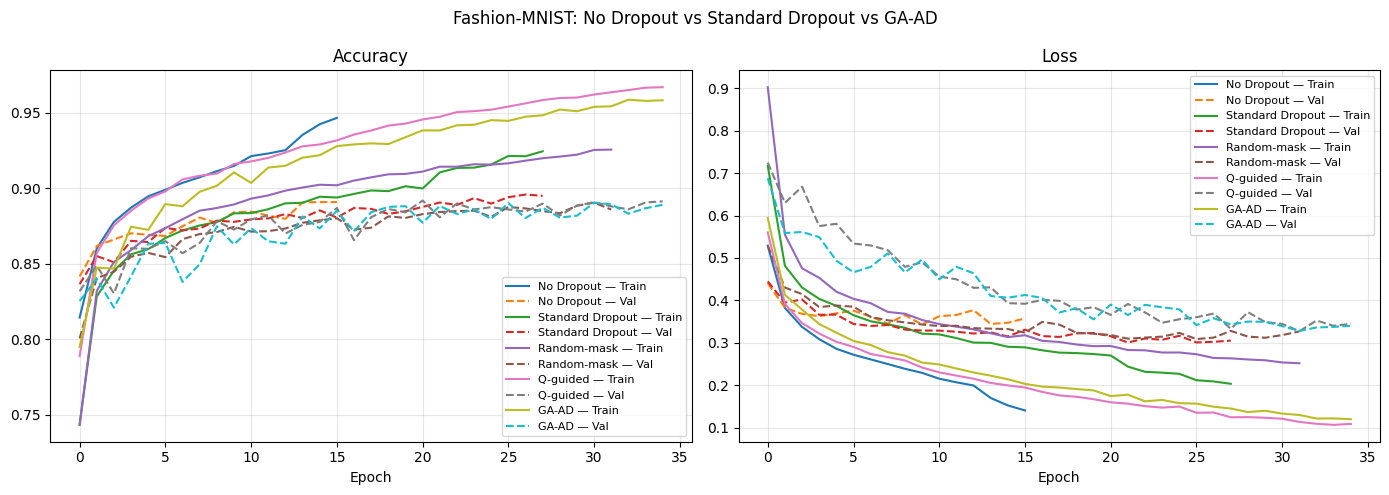

In [11]:
def plot_histories(histories, titles):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for hist, title in zip(histories, titles):
        h = hist.history if hasattr(hist, "history") else hist
        axes[0].plot(h["accuracy"], label=f"{title} — Train")
        axes[0].plot(h["val_accuracy"], linestyle="--", label=f"{title} — Val")
        axes[1].plot(h["loss"], label=f"{title} — Train")
        axes[1].plot(h["val_loss"], linestyle="--", label=f"{title} — Val")
    axes[0].set_title("Accuracy")
    axes[1].set_title("Loss")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    plt.suptitle("Fashion-MNIST: No Dropout vs Standard Dropout vs GA-AD")
    plt.tight_layout()
    plt.show()

plot_histories(
    [history_no_dropout, history_std_dropout, history_random,
     history_qguided, history_gaad],
    ["No Dropout", "Standard Dropout", "Random-mask", "Q-guided", "GA-AD"]
)

## 11. Held-out test evaluation

The official test set is evaluated after training. For custom trainers, inference uses the unmasked network, consistent with the custom training design. Report accuracy, macro precision, macro recall, macro-F1, classification report, and confusion matrix.

HELD-OUT OFFICIAL TEST RESULTS

No Dropout
Loss             : 0.3294
Accuracy         : 0.8901
Macro Precision  : 0.8906
Macro Recall     : 0.8901
Macro F1         : 0.8892

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.8109    0.8790    0.8436      1000
     Trouser     0.9889    0.9770    0.9829      1000
    Pullover     0.7859    0.8370    0.8107      1000
       Dress     0.8868    0.9090    0.8978      1000
        Coat     0.8146    0.8480    0.8310      1000
      Sandal     0.9674    0.9490    0.9581      1000
       Shirt     0.7801    0.6420    0.7043      1000
     Sneaker     0.9116    0.9690    0.9394      1000
         Bag     0.9886    0.9580    0.9731      1000
  Ankle boot     0.9709    0.9330    0.9516      1000

    accuracy                         0.8901     10000
   macro avg     0.8906    0.8901    0.8892     10000
weighted avg     0.8906    0.8901    0.8892     10000



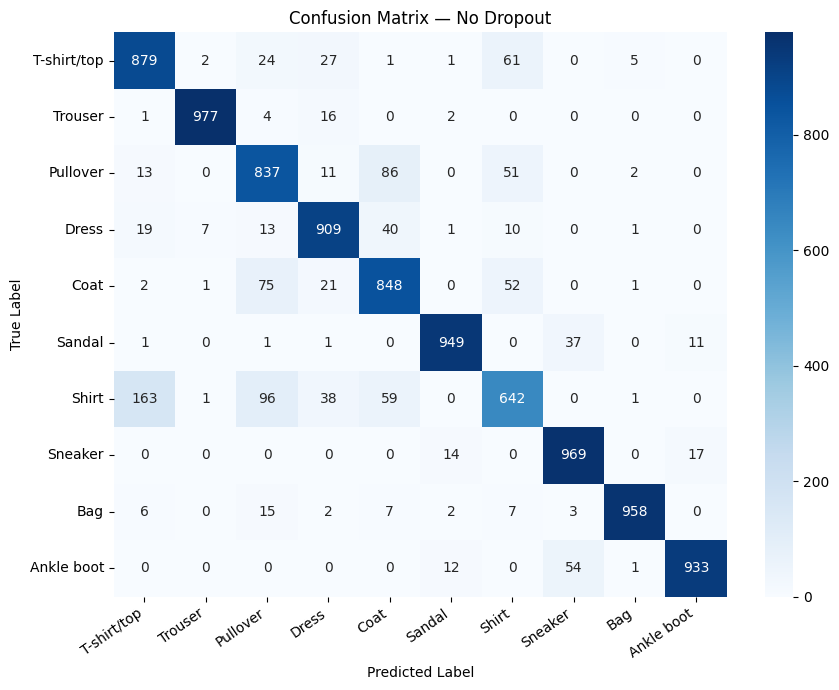


Standard Dropout 0.30
Loss             : 0.2921
Accuracy         : 0.8944
Macro Precision  : 0.8945
Macro Recall     : 0.8944
Macro F1         : 0.8931

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.7886    0.8990    0.8402      1000
     Trouser     0.9831    0.9880    0.9855      1000
    Pullover     0.8408    0.8080    0.8241      1000
       Dress     0.9248    0.9100    0.9173      1000
        Coat     0.7998    0.8830    0.8394      1000
      Sandal     0.9814    0.9480    0.9644      1000
       Shirt     0.7666    0.6240    0.6880      1000
     Sneaker     0.9272    0.9550    0.9409      1000
         Bag     0.9818    0.9700    0.9759      1000
  Ankle boot     0.9514    0.9590    0.9552      1000

    accuracy                         0.8944     10000
   macro avg     0.8945    0.8944    0.8931     10000
weighted avg     0.8945    0.8944    0.8931     10000



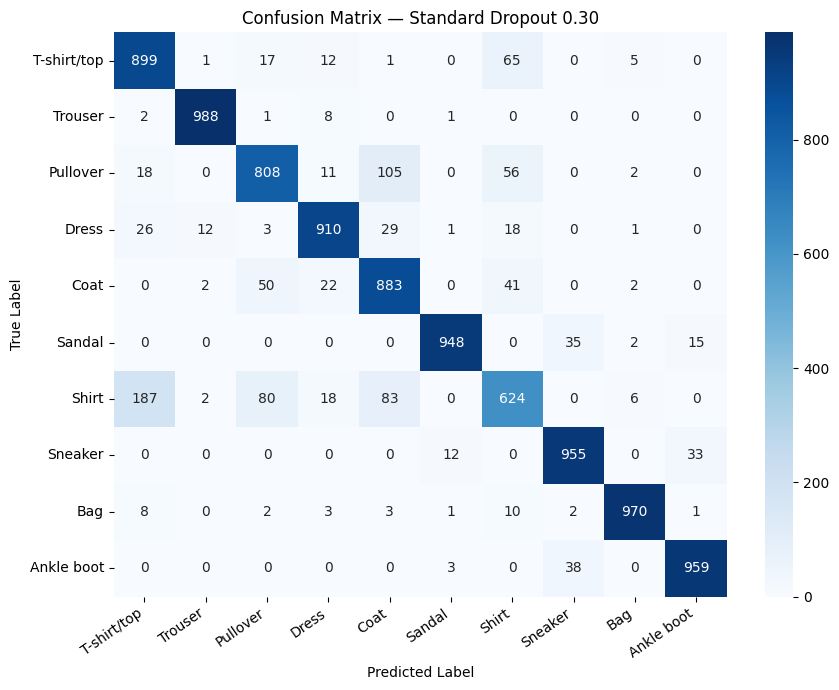


Random-mask
Loss             : 0.3106
Accuracy         : 0.8857
Macro Precision  : 0.8851
Macro Recall     : 0.8857
Macro F1         : 0.8848

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.8420    0.8100    0.8257      1000
     Trouser     0.9821    0.9850    0.9835      1000
    Pullover     0.8141    0.7970    0.8055      1000
       Dress     0.8743    0.9180    0.8956      1000
        Coat     0.7765    0.8510    0.8120      1000
      Sandal     0.9803    0.9450    0.9623      1000
       Shirt     0.7388    0.6620    0.6983      1000
     Sneaker     0.9137    0.9630    0.9377      1000
         Bag     0.9683    0.9790    0.9736      1000
  Ankle boot     0.9614    0.9470    0.9542      1000

    accuracy                         0.8857     10000
   macro avg     0.8851    0.8857    0.8848     10000
weighted avg     0.8851    0.8857    0.8848     10000



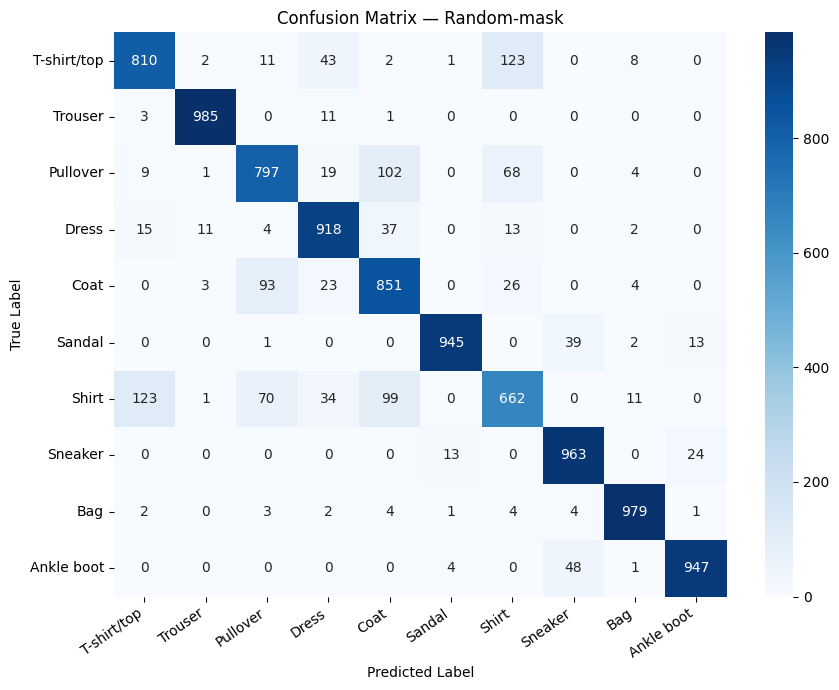


Q-guided low-Q dropout
Loss             : 0.3150
Accuracy         : 0.8926
Macro Precision  : 0.8928
Macro Recall     : 0.8926
Macro F1         : 0.8918

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.8259    0.8680    0.8464      1000
     Trouser     0.9929    0.9820    0.9874      1000
    Pullover     0.7785    0.8610    0.8177      1000
       Dress     0.8763    0.9350    0.9047      1000
        Coat     0.8603    0.7820    0.8193      1000
      Sandal     0.9566    0.9690    0.9627      1000
       Shirt     0.7593    0.6720    0.7130      1000
     Sneaker     0.9265    0.9580    0.9420      1000
         Bag     0.9796    0.9610    0.9702      1000
  Ankle boot     0.9720    0.9380    0.9547      1000

    accuracy                         0.8926     10000
   macro avg     0.8928    0.8926    0.8918     10000
weighted avg     0.8928    0.8926    0.8918     10000



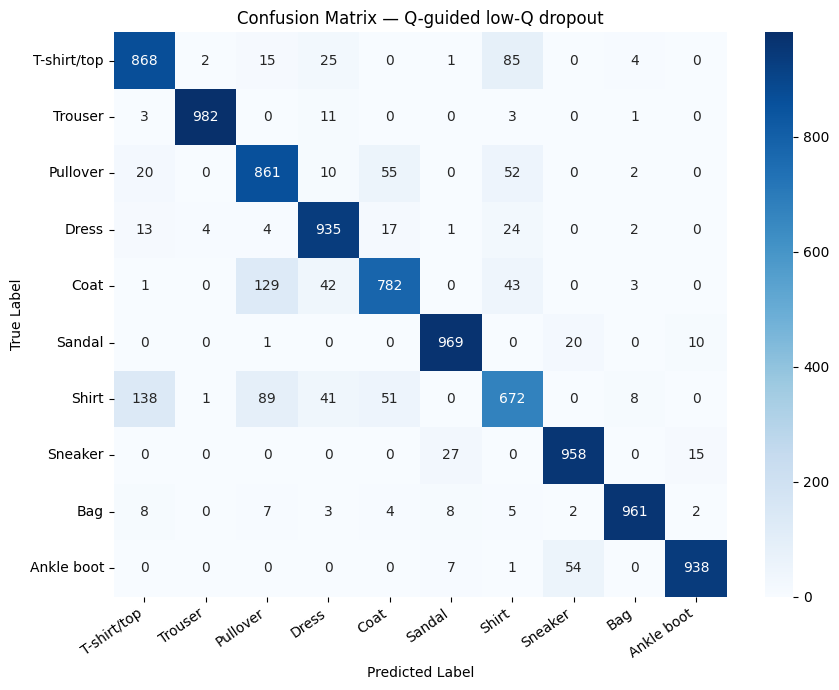


GA-AD elite-resampling
Loss             : 0.3155
Accuracy         : 0.8936
Macro Precision  : 0.8945
Macro Recall     : 0.8936
Macro F1         : 0.8929

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top     0.8352    0.8720    0.8532      1000
     Trouser     0.9801    0.9870    0.9836      1000
    Pullover     0.7675    0.8750    0.8178      1000
       Dress     0.8798    0.9220    0.9004      1000
        Coat     0.8909    0.7510    0.8150      1000
      Sandal     0.9659    0.9630    0.9644      1000
       Shirt     0.7582    0.6960    0.7258      1000
     Sneaker     0.9481    0.9320    0.9400      1000
         Bag     0.9760    0.9740    0.9750      1000
  Ankle boot     0.9432    0.9640    0.9535      1000

    accuracy                         0.8936     10000
   macro avg     0.8945    0.8936    0.8929     10000
weighted avg     0.8945    0.8936    0.8929     10000



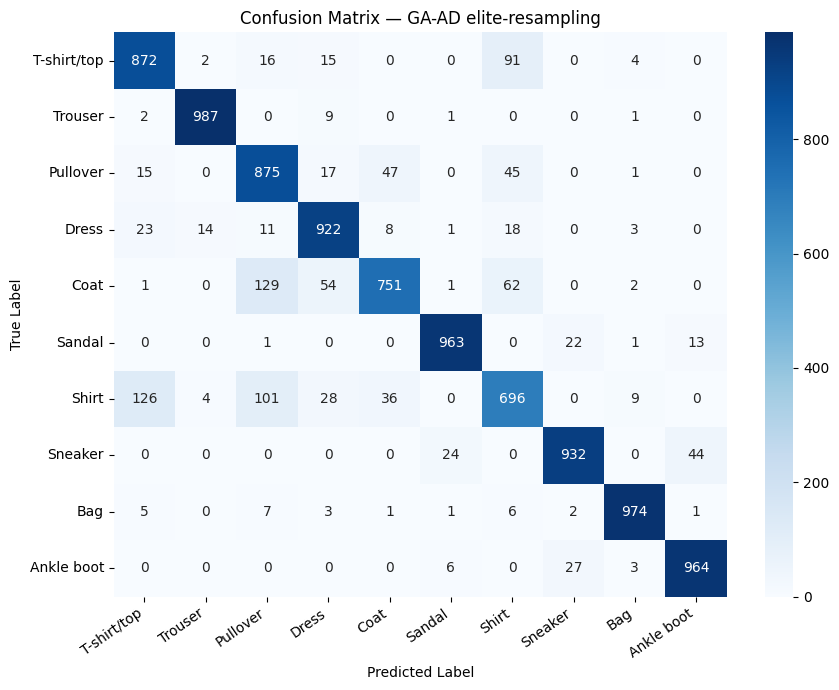

In [14]:

def evaluate_model(model_or_trainer, X, y_true_cat, model_name, is_custom=False):

    y_true = np.argmax(y_true_cat, axis=1)

    if is_custom:
        # Custom GA-AD trainer evaluation
        loss, acc = model_or_trainer._evaluate(X, y_true_cat)

        predictions = []

        for i in range(0, len(X), 512):
            batch = tf.constant(X[i:i + 512], dtype=tf.float32)

            # FIX: Call _forward without the unsupported training argument
            logits = model_or_trainer._forward(batch)

            predictions.extend(
                np.argmax(logits.numpy(), axis=1)
            )

        y_pred = np.asarray(predictions)

    else:
        # Standard Keras model evaluation
        probabilities = model_or_trainer.predict(
            X,
            batch_size=512,
            verbose=0
        )

        y_pred = np.argmax(probabilities, axis=1)

        acc = accuracy_score(y_true, y_pred)

        loss = float(-np.mean(np.sum(
            y_true_cat * np.log(
                np.clip(probabilities, 1e-9, 1.0)
            ),
            axis=1
        )))

    # Classification metrics
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    print(f"\n{'=' * 64}")
    print(model_name)
    print(f"{'=' * 64}")

    print(f"Loss             : {loss:.4f}")
    print(f"Accuracy         : {acc:.4f}")
    print(f"Macro Precision  : {precision:.4f}")
    print(f"Macro Recall     : {recall:.4f}")
    print(f"Macro F1         : {f1:.4f}")

    print("\nClassification Report:\n")

    print(classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(f"Confusion Matrix — {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    return {
        "loss": loss,
        "accuracy": acc,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "y_pred": y_pred
    }


# ============================================================
# HELD-OUT OFFICIAL TEST RESULTS
# ============================================================

print("HELD-OUT OFFICIAL TEST RESULTS")

res_no = evaluate_model(
    model_no_dropout,
    X_test,
    y_test,
    "No Dropout"
)

res_std = evaluate_model(
    model_std_dropout,
    X_test,
    y_test,
    "Standard Dropout 0.30"
)

res_random = evaluate_model(
    trainer_random,
    X_test,
    y_test,
    "Random-mask",
    is_custom=True
)

res_q = evaluate_model(
    trainer_qguided,
    X_test,
    y_test,
    "Q-guided low-Q dropout",
    is_custom=True
)

res_ga = evaluate_model(
    trainer_gaad,
    X_test,
    y_test,
    "GA-AD elite-resampling",
    is_custom=True
)


## 12. Quantitative comparison

In [15]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Loss", "Precision (macro)", "Recall (macro)", "F1 (macro)"],
    "No Dropout": [res_no["accuracy"], res_no["loss"], res_no["precision_macro"],
                   res_no["recall_macro"], res_no["f1_macro"]],
    "Standard Dropout": [res_std["accuracy"], res_std["loss"], res_std["precision_macro"],
                         res_std["recall_macro"], res_std["f1_macro"]],
    "Random-mask": [res_random["accuracy"], res_random["loss"], res_random["precision_macro"],
                    res_random["recall_macro"], res_random["f1_macro"]],
    "Q-guided": [res_q["accuracy"], res_q["loss"], res_q["precision_macro"],
                 res_q["recall_macro"], res_q["f1_macro"]],
    "GA-AD": [res_ga["accuracy"], res_ga["loss"], res_ga["precision_macro"],
              res_ga["recall_macro"], res_ga["f1_macro"]]
}).round(4)
display(comparison)

,Metric,No Dropout,Standard Dropout,Random-mask,Q-guided,GA-AD
0,Accuracy,0.8901,0.8944,0.8857,0.8926,0.8936
1,Loss,0.3294,0.2921,0.3106,0.3150,0.3155
2,Precision (macro),0.8906,0.8945,0.8851,0.8928,0.8945
3,Recall (macro),0.8901,0.8944,0.8857,0.8926,0.8936
4,F1 (macro),0.8892,0.8931,0.8848,0.8918,0.8929


## 13. Per-class performance and GA diagnostics

The GA holdout metrics are post-training diagnostics only. They are not fitness scores and must not be used to choose a mask, hyperparameter, or model.

In [16]:
per_class_f1 = pd.DataFrame({
    "Class": CLASS_NAMES,
    "No Dropout": f1_score(y_test_int, res_no["y_pred"], average=None),
    "Standard Dropout": f1_score(y_test_int, res_std["y_pred"], average=None),
    "Random-mask": f1_score(y_test_int, res_random["y_pred"], average=None),
    "Q-guided": f1_score(y_test_int, res_q["y_pred"], average=None),
    "GA-AD": f1_score(y_test_int, res_ga["y_pred"], average=None)
}).set_index("Class").round(4)
display(per_class_f1)

print("GA holdout diagnostic (loss, accuracy):", trainer_gaad.ga_holdout_metrics)

,No Dropout,Standard Dropout,Random-mask,Q-guided,GA-AD
Class,,,,,
T-shirt/top,0.8436,0.8402,0.8257,0.8464,0.8532
Trouser,0.9829,0.9855,0.9835,0.9874,0.9836
Pullover,0.8107,0.8241,0.8055,0.8177,0.8178
Dress,0.8978,0.9173,0.8956,0.9047,0.9004
Coat,0.8310,0.8394,0.8120,0.8193,0.8150
Sandal,0.9581,0.9644,0.9623,0.9627,0.9644
Shirt,0.7043,0.6880,0.6983,0.7130,0.7258
Sneaker,0.9394,0.9409,0.9377,0.9420,0.9400
Bag,0.9731,0.9759,0.9736,0.9702,0.9750


GA holdout diagnostic (loss, accuracy): (0.32367371767759323, 0.890625)


## 14. Methodological interpretation and required ablations

### What changed relative to the previous Fashion-MNIST notebook
1. The experiment now includes the actual **GA-AD genetic optimizer**, not only random and Q-guided masking.
2. Q is an EMA of mean `|activation × gradient|`, with robust percentile normalization.
3. The redundant polynomial descriptor is removed.
4. GA fitness uses retained Q importance only; validation loss and GA-holdout performance never score candidate masks.
5. The GA maintains a diverse elite pool, and a new elite mask is sampled per mini-batch.
6. The final partial mini-batch is processed.
7. Random-mask, Q-guided, and GA-AD are trained under a matched fixed dropout rate and common data partitions.

### Interpretation constraints
- GA fitness is an importance-retention heuristic; it may behave like structured pruning and is not itself evidence of improved generalization.
- Structured neuron masks are shared across examples in a mini-batch. Conventional Keras dropout uses element-wise stochastic masks, so the methods differ in mask granularity.
- A GA advantage must be demonstrated over the cheaper Q-guided control, not merely over no dropout.
- One seed and one fixed split are insufficient for a publication-level claim.

### Required ablations
1. Random mask vs low-Q guided masking vs reverse high-Q masking.
2. Mean absolute gradient vs `|activation × gradient|`.
3. GA elite resampling vs a single best mask vs Q-guided sampling.
4. Fixed `p=0.30` vs an outer-loop rate grid.
5. At least 5–10 seeds and, preferably, repeated stratified splits.
6. Record candidate-mask evaluations, wall-clock time, and performance under compute-matched budgets.

## 15. Conclusion

This Fashion-MNIST notebook now follows the revised GA-AD methodology of the MNIST digit-recognition implementation. The primary scientific question is whether GA elite-resampling provides measurable benefit beyond Q-guided sampling and random structured masking at the same dropout rate.

Do not claim GA-AD superiority unless the result is consistent across multiple seeds, compute-matched controls, and an untouched final test protocol. The optional reverse-Q and score-mode ablations should be run before making claims about the direction or form of neuron importance.